In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [4]:
proj_data = pd.read_csv('diabetes-data.csv')

In [5]:
proj_data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
proj_data.describe()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [7]:
proj_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [8]:
proj_data_copy = proj_data.copy(deep = True)


In [9]:
proj_data_copy[['Glucose', 'BloodPressure','SkinThickness','Insulin','BMI']] = \
proj_data_copy[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin','BMI']].replace(0, np.nan)

In [10]:
print(proj_data_copy.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


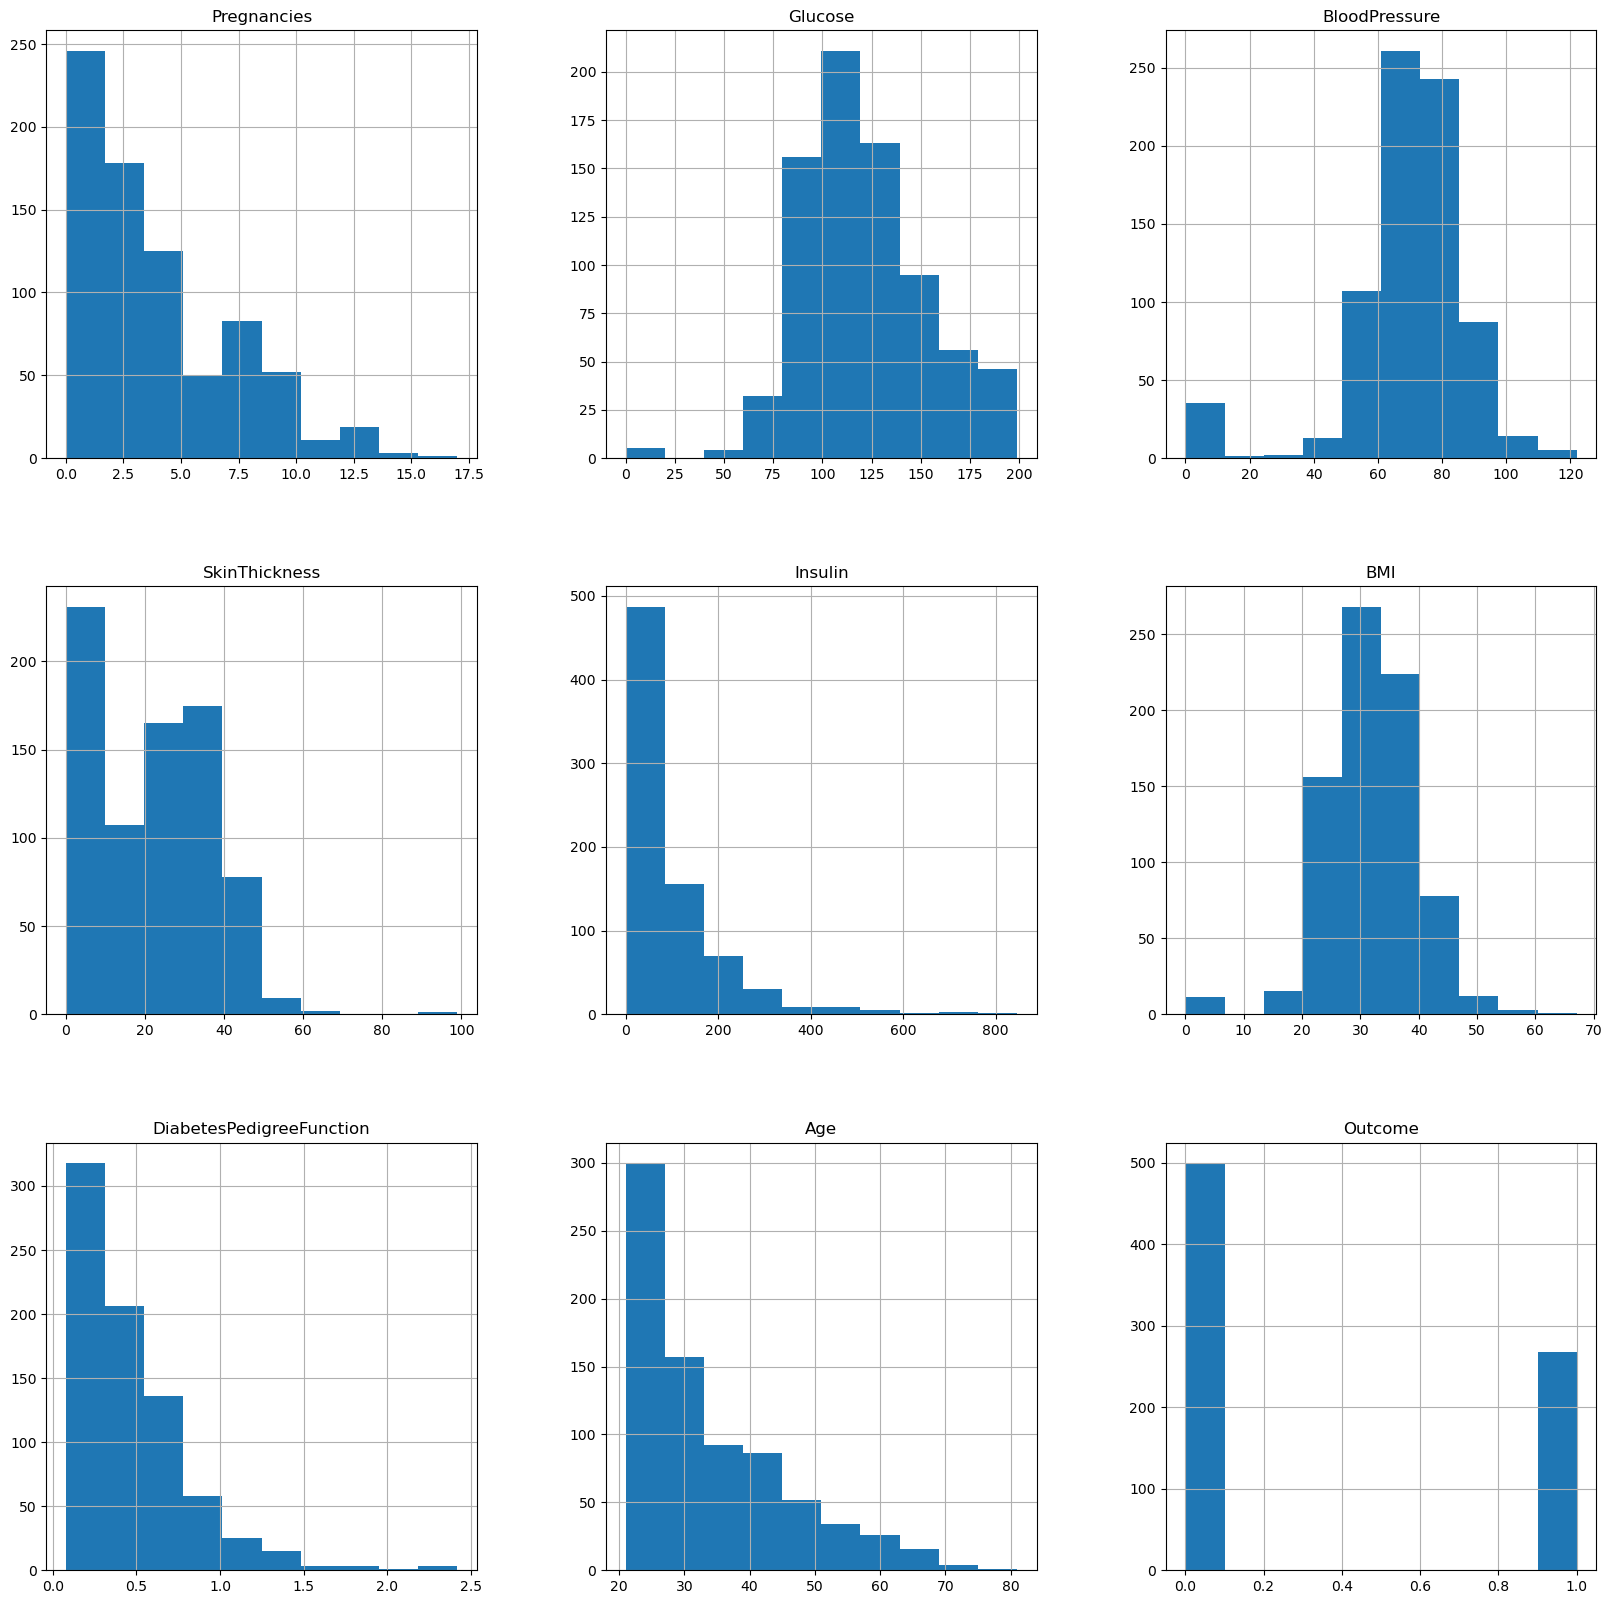

In [11]:
hplot = proj_data.hist(figsize = (20,20))

In [12]:
    proj_data_copy['Glucose'] = proj_data_copy['Glucose'].fillna(proj_data_copy['Glucose'].mean())

In [13]:
proj_data_copy['BloodPressure'] = proj_data_copy['BloodPressure'].fillna(proj_data_copy['BloodPressure'].mean())

In [14]:
proj_data_copy['SkinThickness'] = proj_data_copy['SkinThickness'].fillna(proj_data_copy['SkinThickness'].median())

In [15]:
proj_data_copy['Insulin'] = proj_data_copy['Insulin'].fillna(proj_data_copy['Insulin'].median())

In [16]:
proj_data_copy['BMI'] = proj_data_copy['BMI'].fillna(proj_data_copy['BMI'].median())

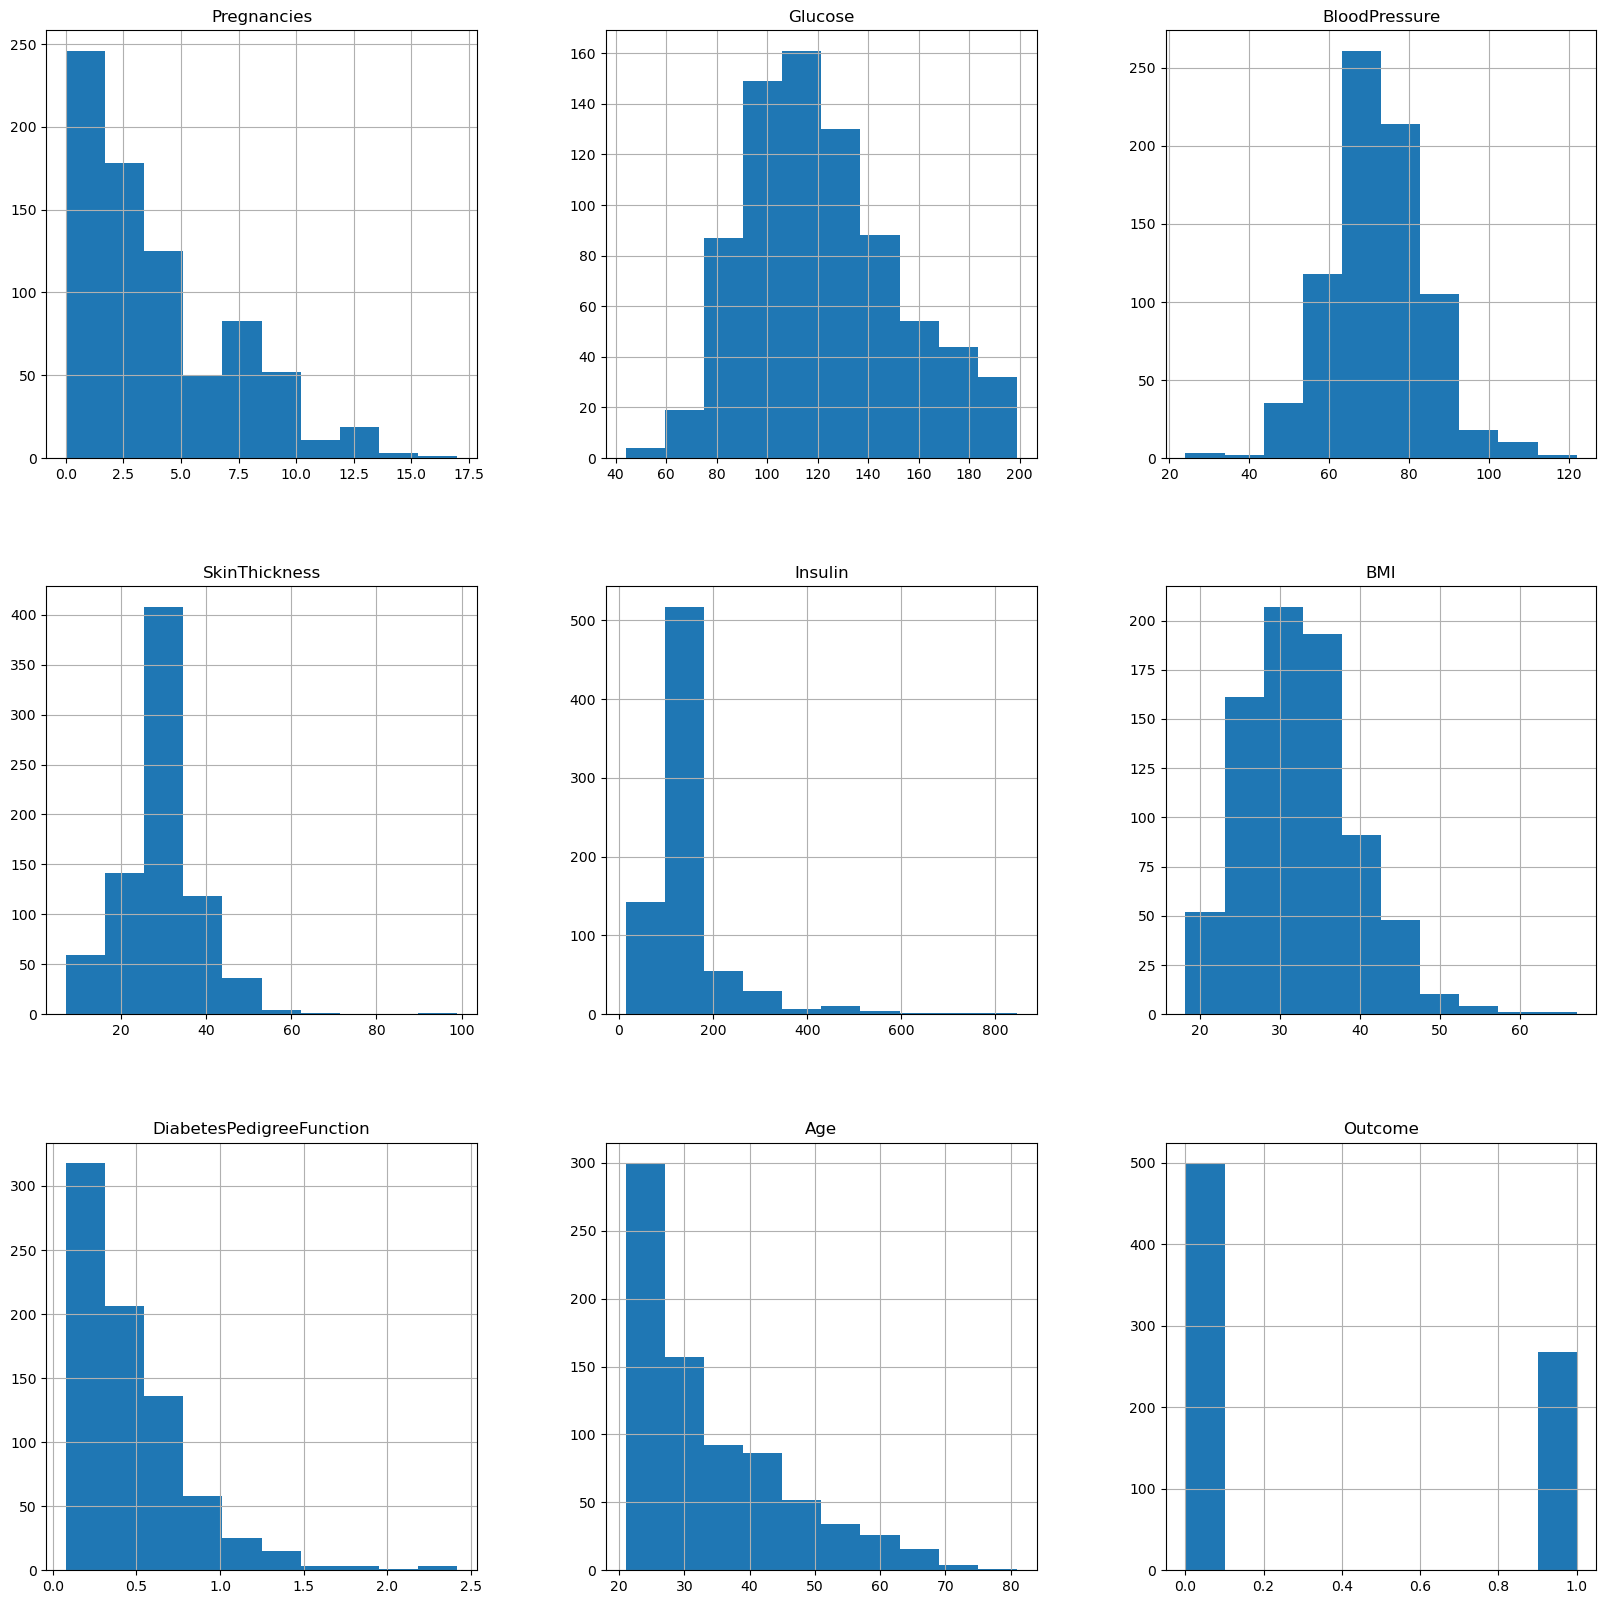

In [17]:
hplot = proj_data_copy.hist(figsize = (20,20))

In [18]:
proj_data.shape
(768, 9)

(768, 9)

In [19]:
print(proj_data.Outcome.value_counts())


Outcome
0    500
1    268
Name: count, dtype: int64


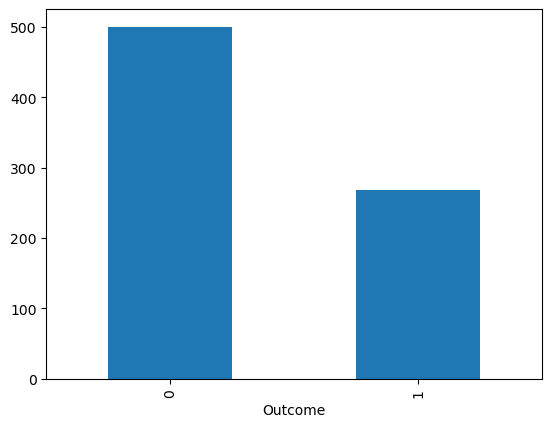

In [20]:
p=proj_data.Outcome.value_counts().plot(kind="bar")

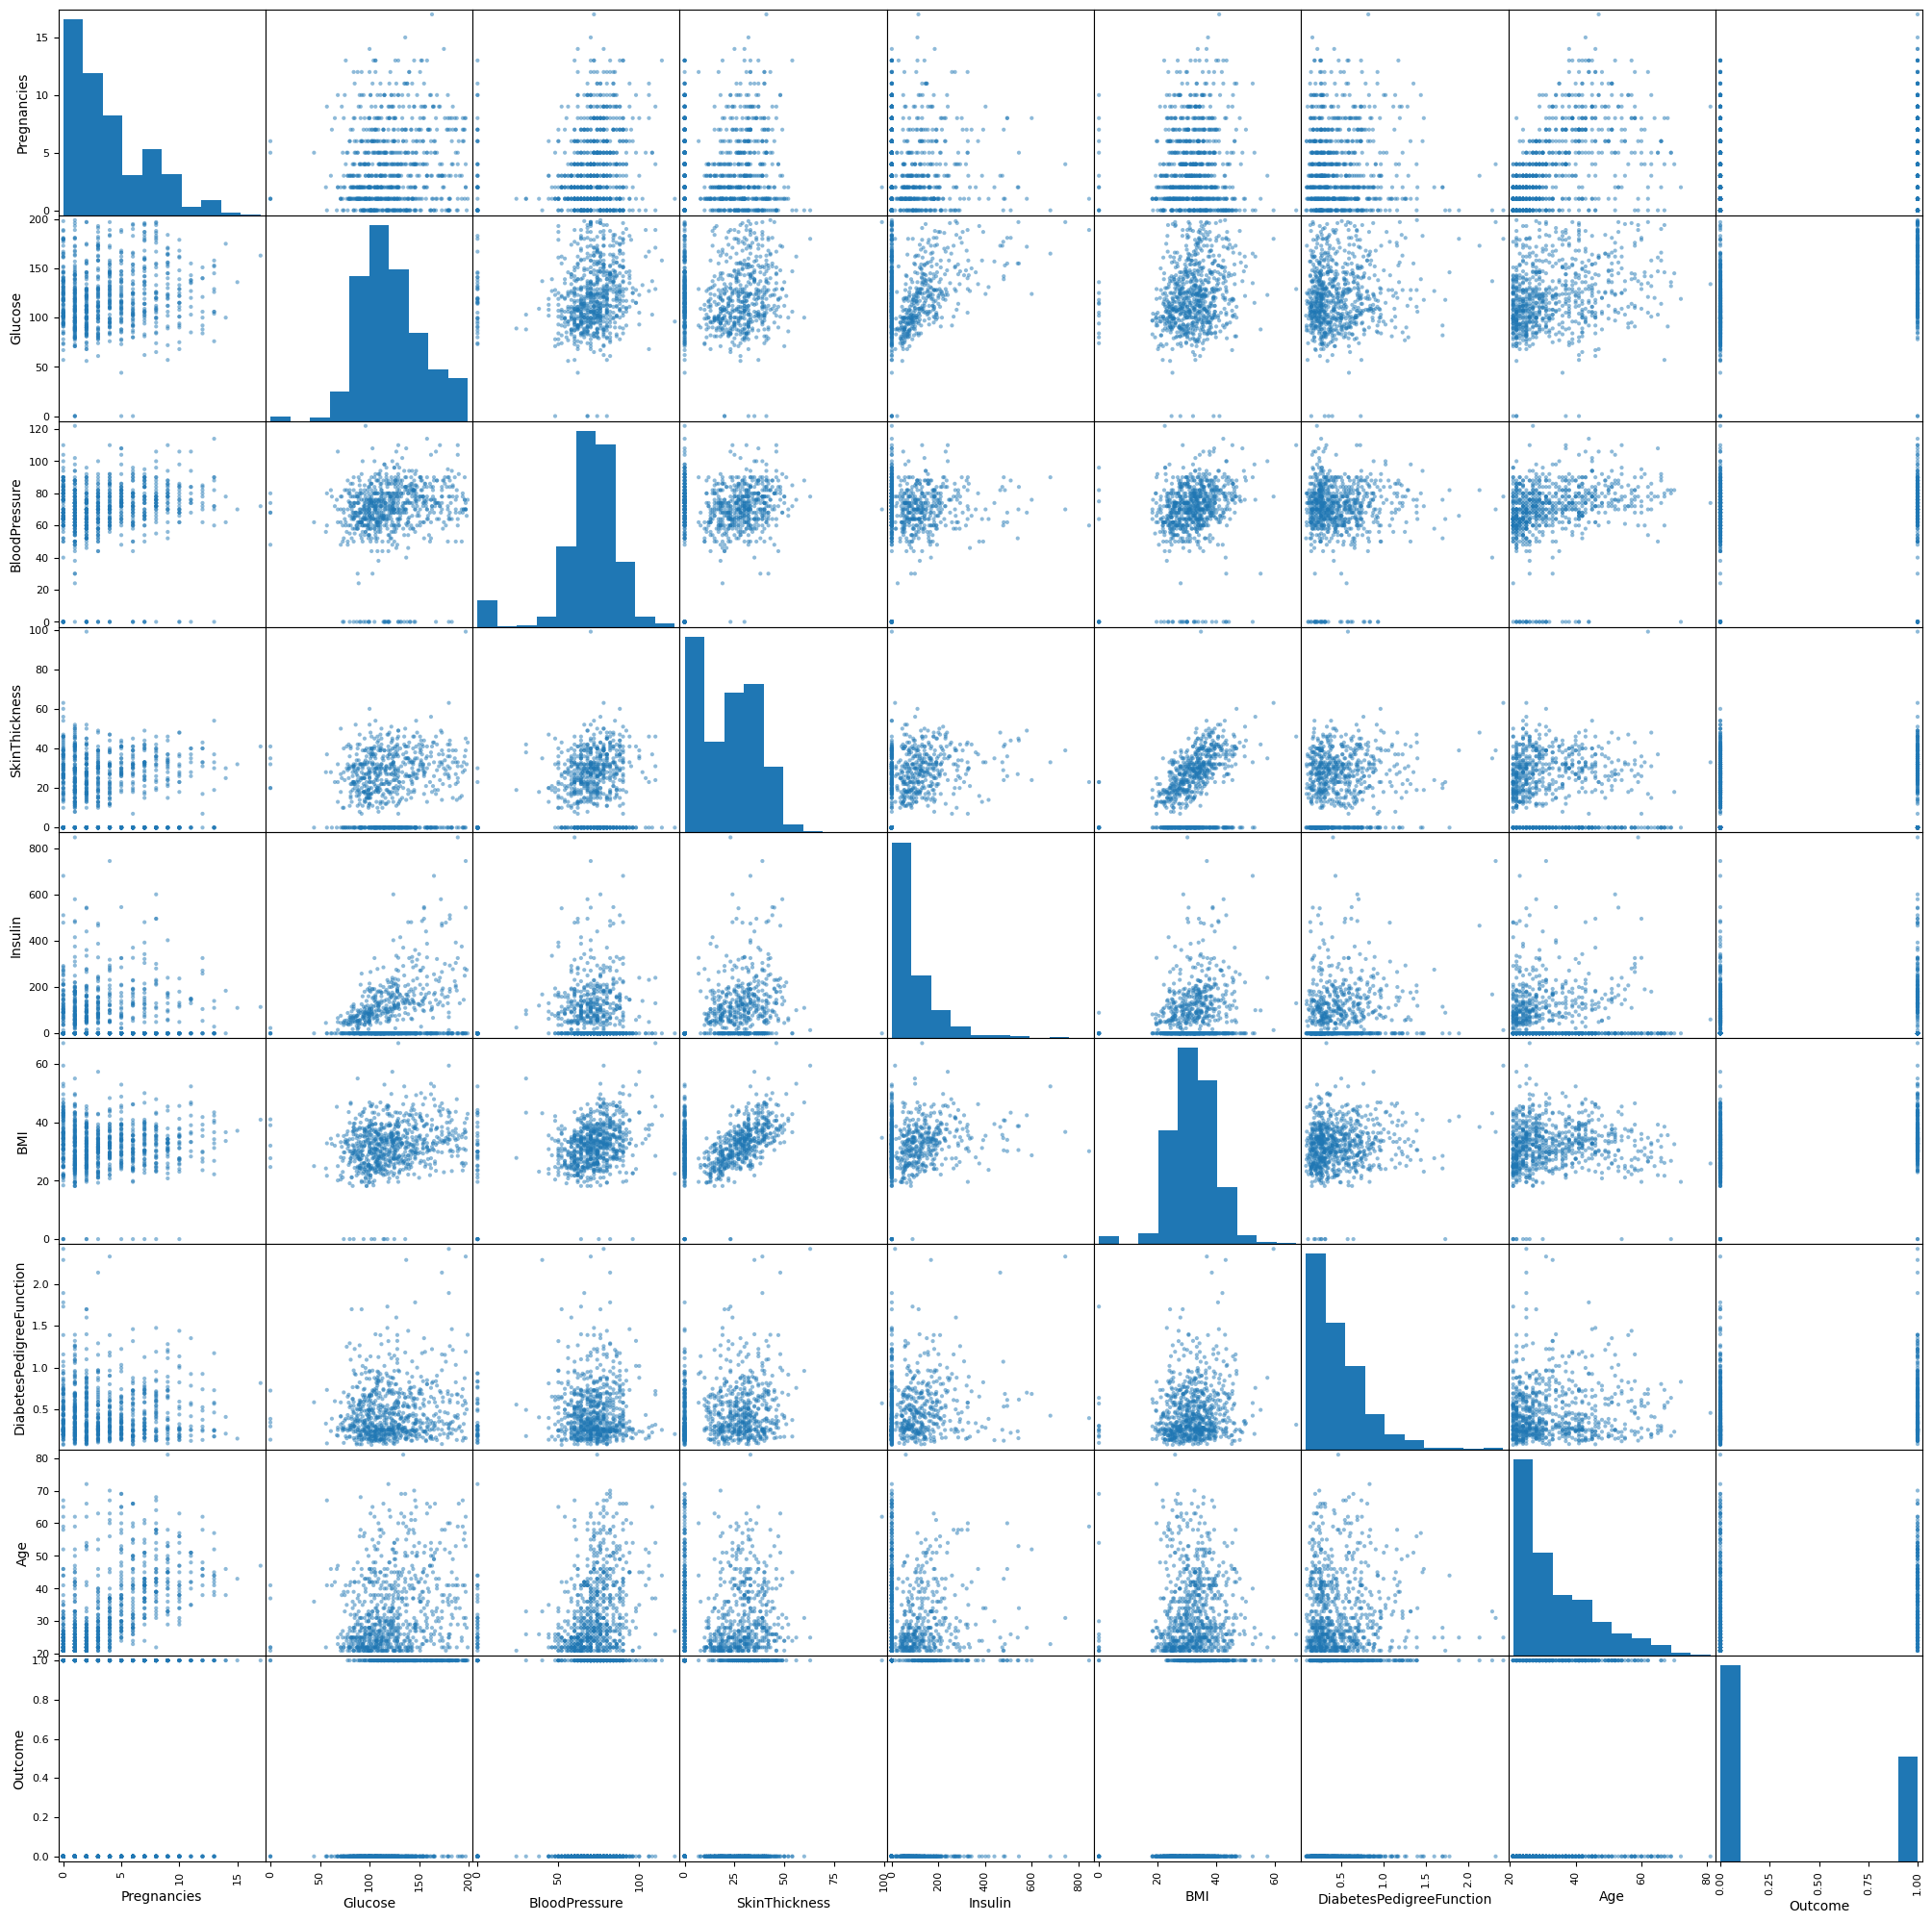

In [21]:
from pandas.plotting import scatter_matrix
p=scatter_matrix(proj_data,figsize=(25, 25))

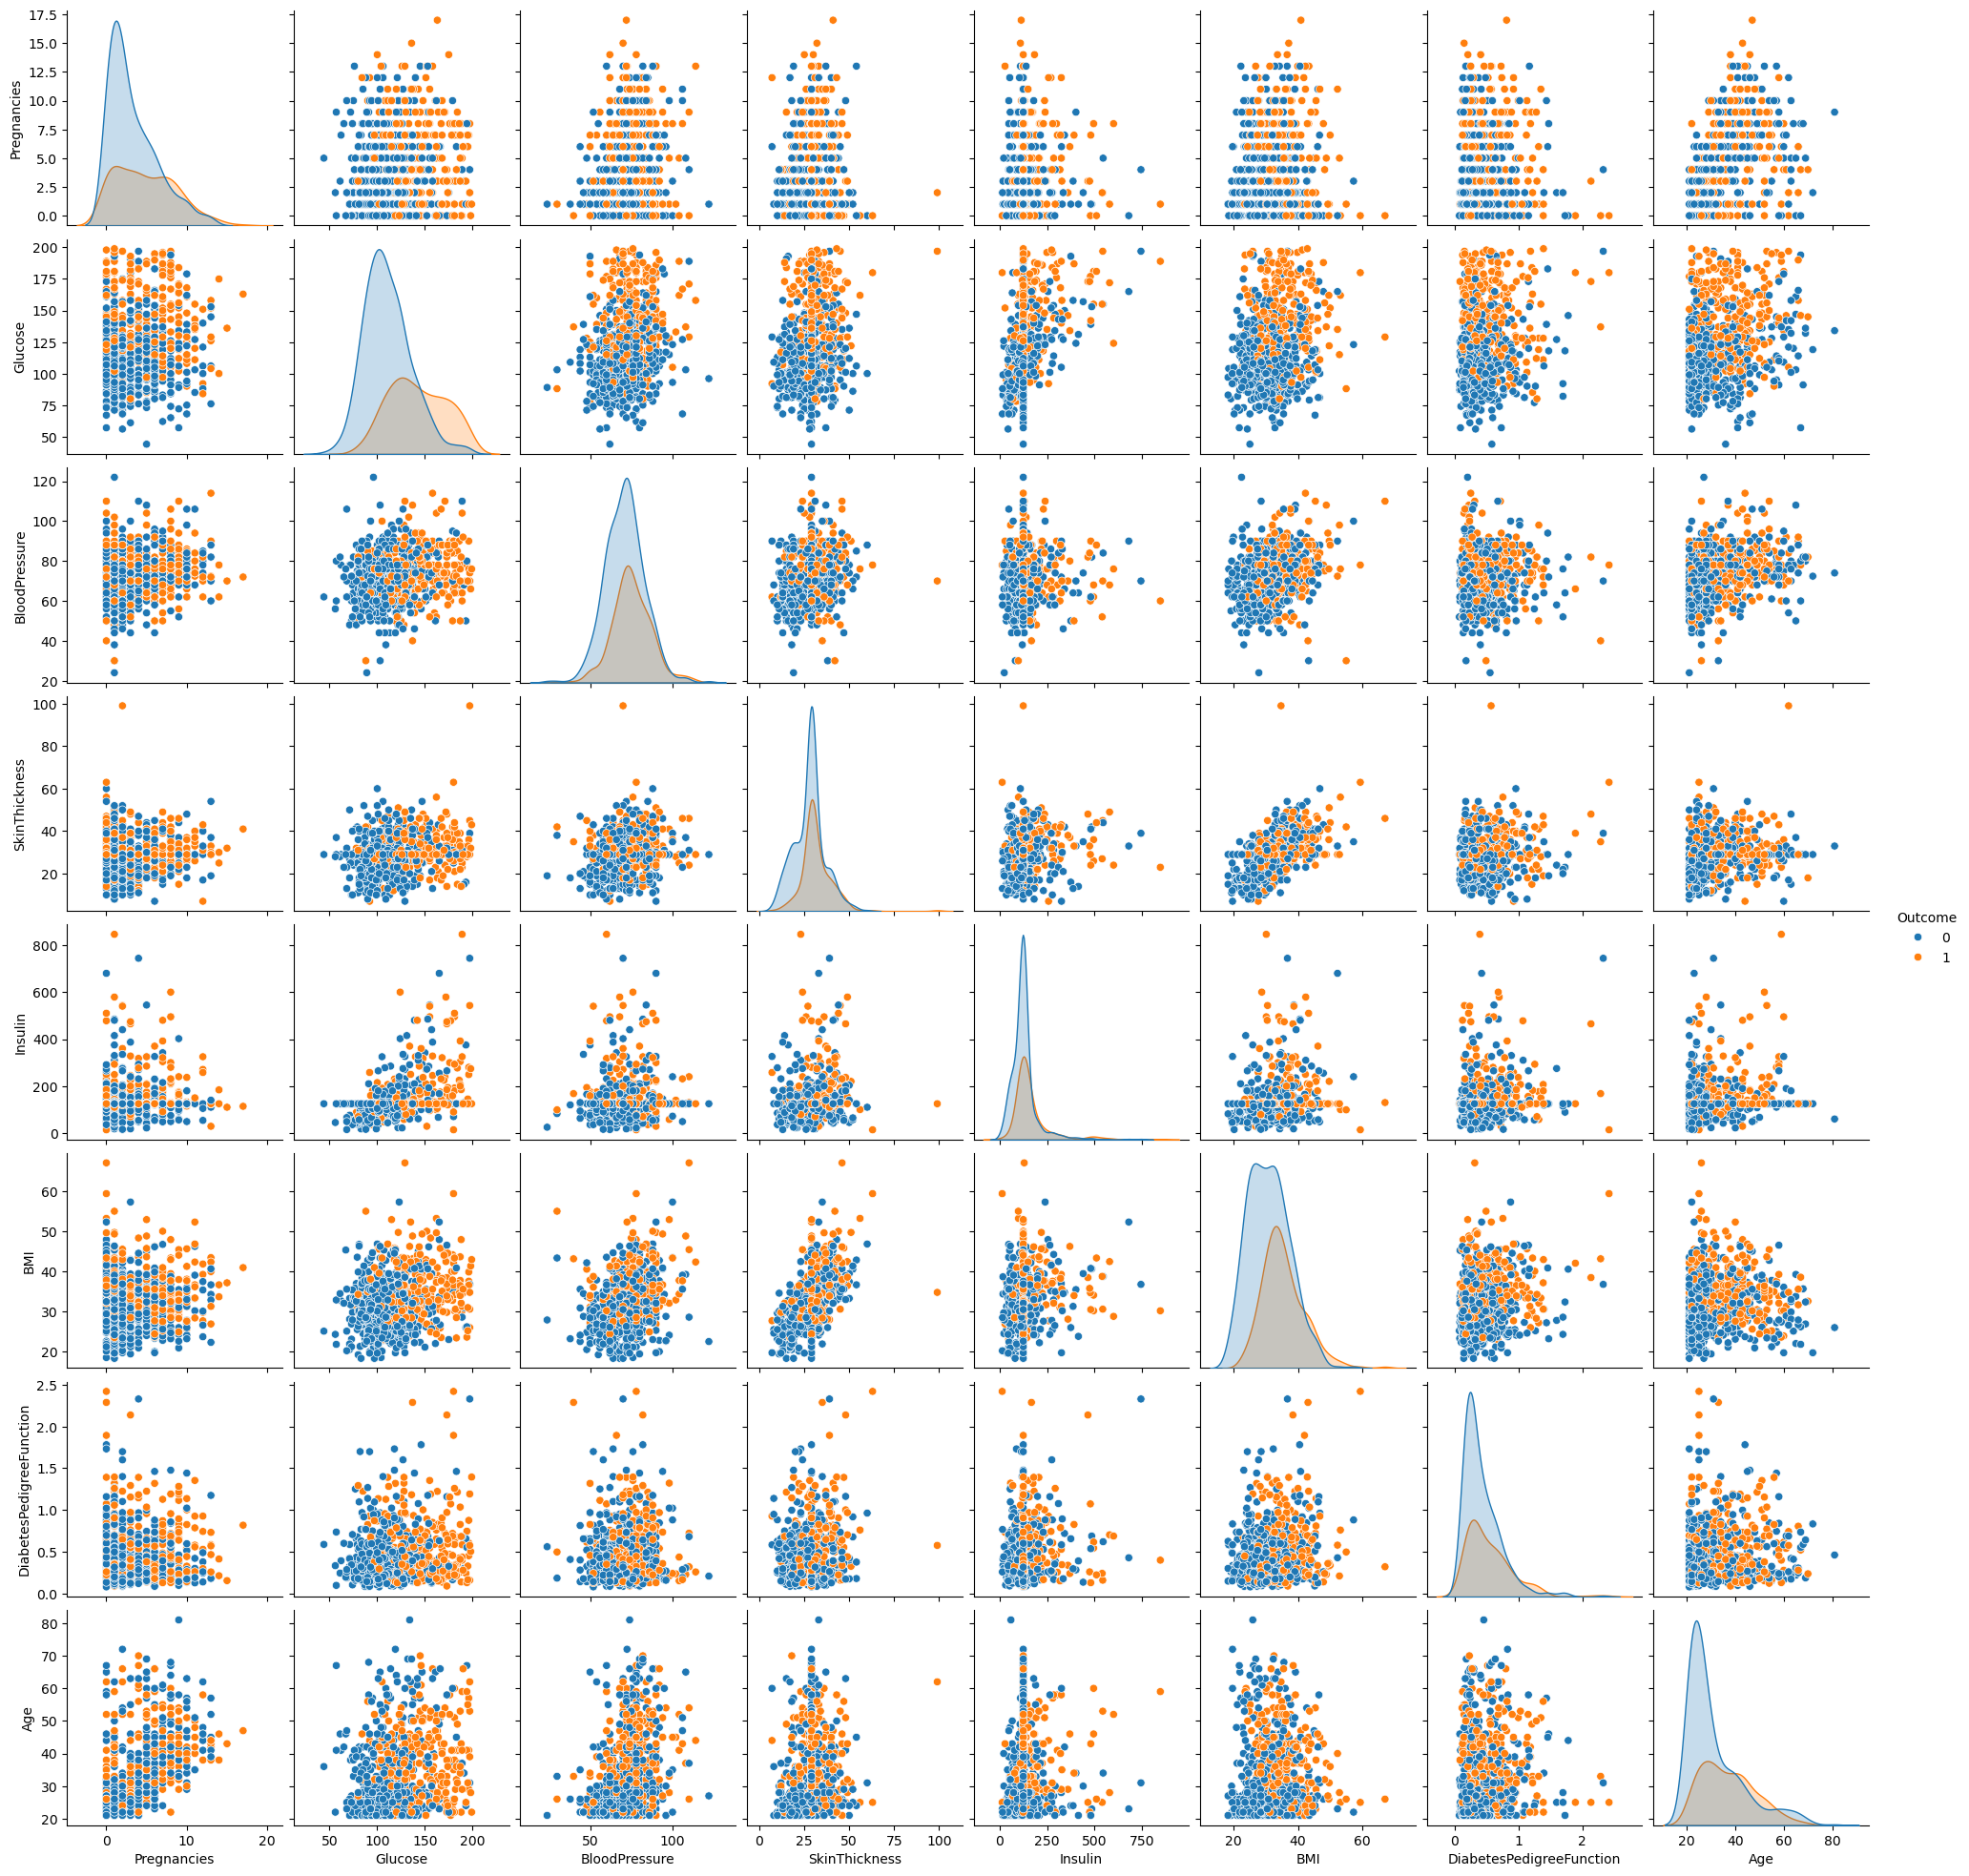

In [22]:
p = sns.pairplot(proj_data_copy, hue='Outcome')

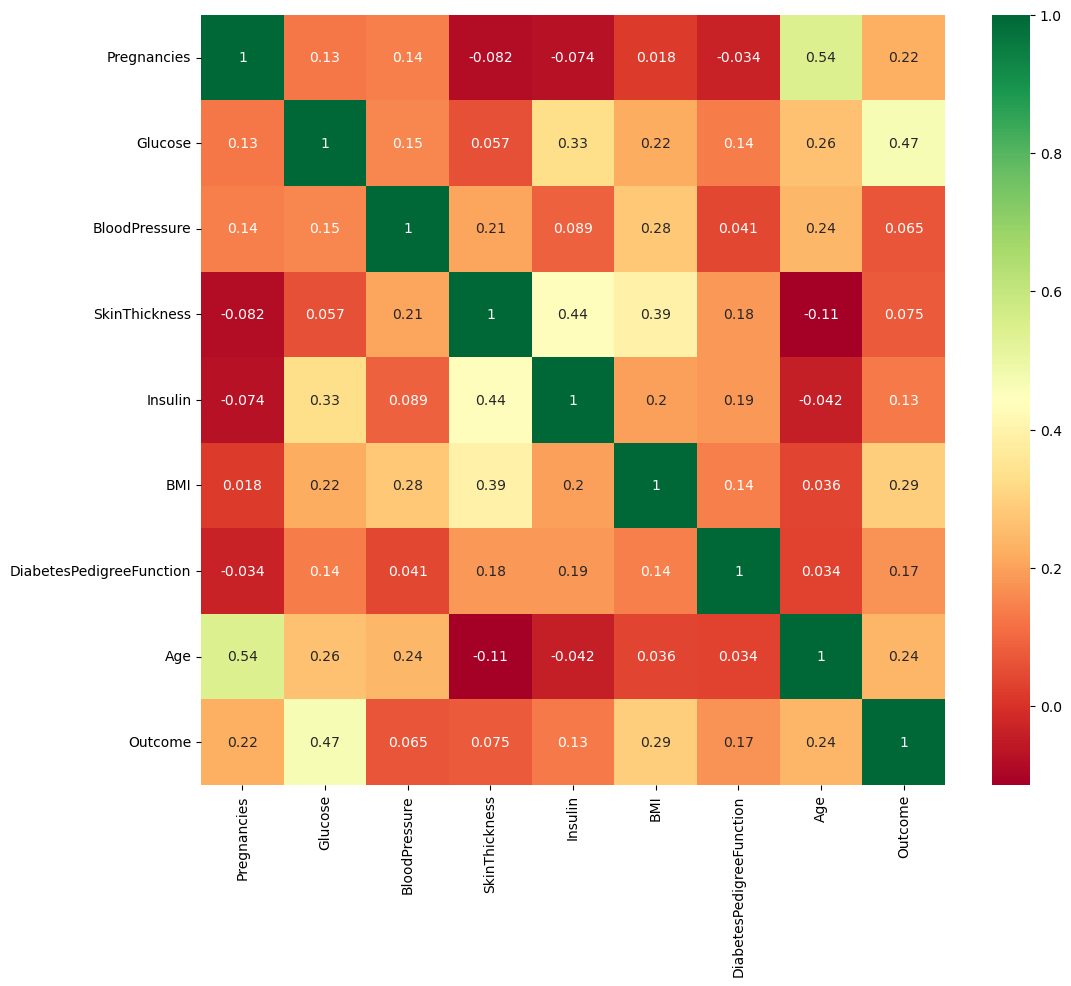

In [23]:
plt.figure(figsize=(12,10))
p=sns.heatmap(proj_data.corr(), annot=True,cmap ='RdYlGn')

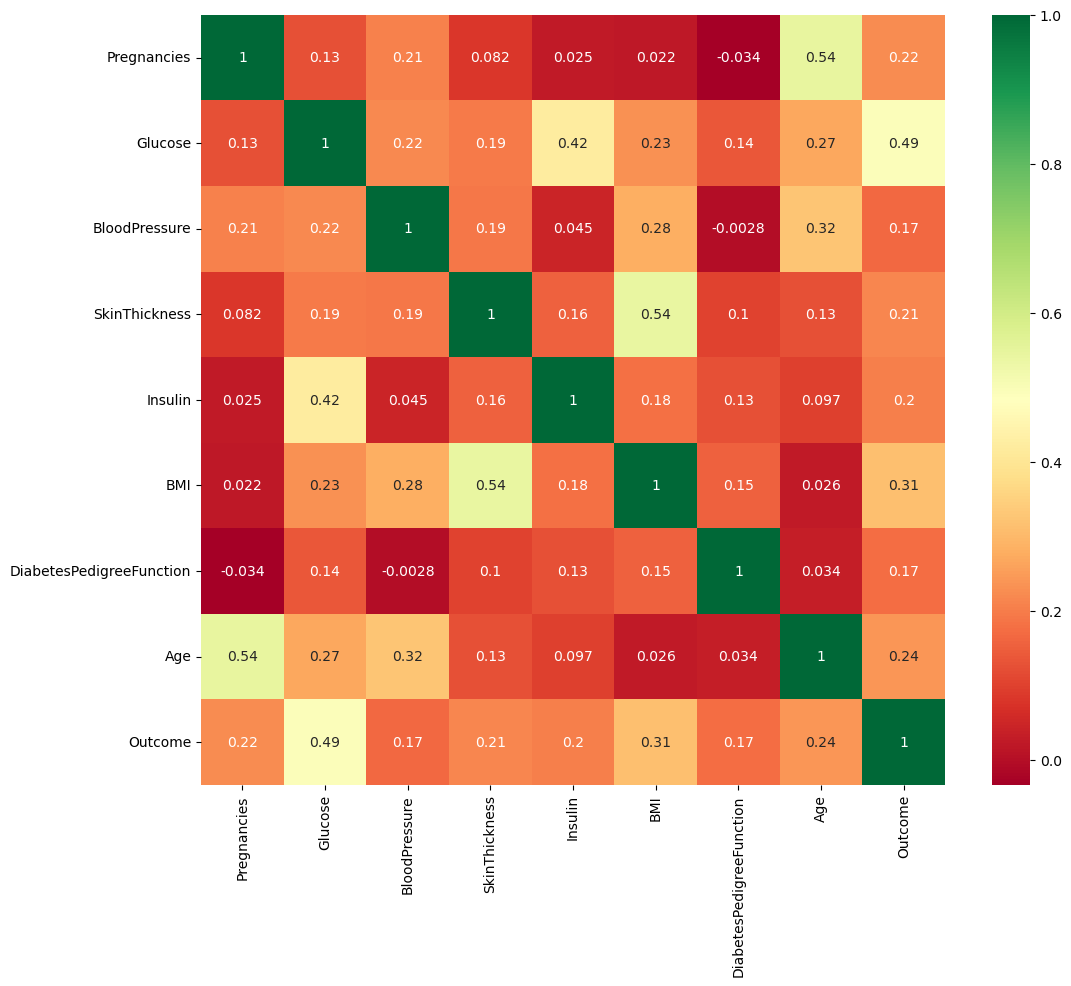

In [25]:
plt.figure(figsize=(12,10))
p = sns.heatmap(proj_data_copy.corr(), annot=True, cmap='RdYlGn')

In [26]:
from sklearn.preprocessing import StandardScaler


In [27]:
scale_X = StandardScaler()


In [28]:
X = scale_X.fit_transform(proj_data_copy.drop(["Outcome"],axis = 1),)


In [29]:
X = pd.DataFrame(X,columns=['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'])

In [30]:
X.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.639947,0.865108,-0.033518,0.670643,-0.181541,0.166619,0.468492,1.425995
1,-0.844885,-1.206162,-0.529859,-0.012301,-0.181541,-0.852200,-0.365061,-0.190672
2,1.233880,2.015813,-0.695306,-0.012301,-0.181541,-1.332500,0.604397,-0.105584
3,-0.844885,-1.074652,-0.529859,-0.695245,-0.540642,-0.633881,-0.920763,-1.041549
4,-1.141852,0.503458,-2.680669,0.670643,0.316566,1.549303,5.484909,-0.020496


In [31]:
y = proj_data_copy.Outcome


In [32]:
from sklearn.model_selection import train_test_split


In [33]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=1/3,random_state=42,
stratify=y)

In [34]:
from sklearn.neighbors import KNeighborsClassifier


In [35]:
testing_score = []
training_score = []

In [37]:
for i in range(1,15):
 knn = KNeighborsClassifier(i)
 knn.fit(X_train,y_train)
 training_score.append(knn.score(X_train,y_train))
 testing_score.append(knn.score(X_test,y_test))

In [38]:
max_training_score = max(training_score)
train_scores_ind = [i for i, v in enumerate(training_score) if v == max_training_score]
print('Max training score {} % and k = {}'.format(max_training_score*100,list(map(lambda x:
x+1, train_scores_ind))))

Max training score 100.0 % and k = [1]


In [39]:
max_testing_score = max(testing_score)


In [40]:
test_scores_ind = [i for i, v in enumerate(testing_score) if v == max_testing_score]


In [41]:
print('Max testing score {} % and k = {}'.format(max_testing_score*100,list(map(lambda x:
x+1, test_scores_ind)))) 


Max testing score 76.5625 % and k = [11]


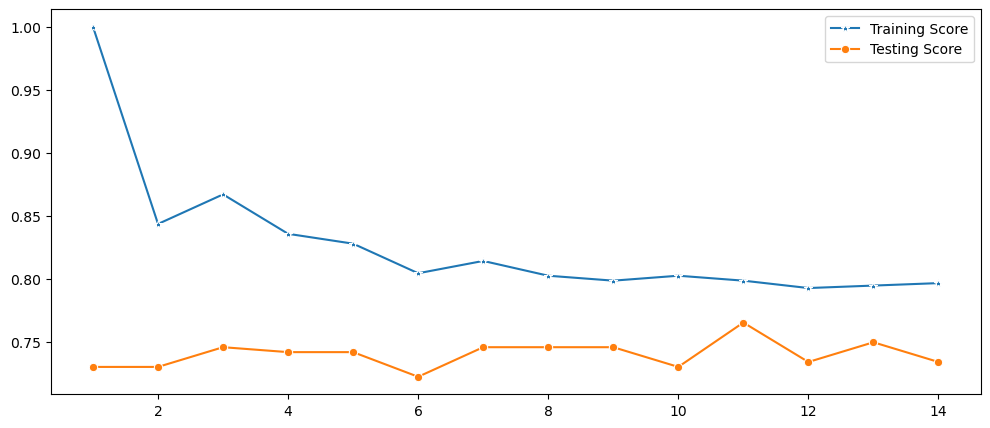

In [43]:
plt.figure(figsize=(12,5))
pplot = sns.lineplot(x=range(1,15), y=training_score, marker='*', label='Training Score')
pplot = sns.lineplot(x=range(1,15), y=testing_score, marker='o', label='Testing Score')

In [44]:
knn = KNeighborsClassifier(11)


In [45]:
knn.fit(X_train,y_train)
knn.score(X_test,y_test)

0.765625